# 15 · English Learning Events (synthetic): results

Supports thesis Sections 4.3 (search) and 4.4 (English results). **Synthetic data**: results describe the generator.

1. the validation-only search: DKT/SAKT/AKT from the curated run (read-only), DKVMN/SAINT with the same 8 trials;
2. the five models in one workspace, default configuration (as the curated run kept), 3 seeds;
3. reproduction check: the workspace DKT/SAKT/AKT against the curated checkpoints' test metrics.

**Where to run.** Locally (recommended): `.venv-kt` with `requirements-analysis.txt`, started from the repository; no GPU needed.
**On Colab (CPU runtime is enough):** upload `ednet_colab_bundle.zip` (built by `knowledge_tracing/make_colab_bundle.py`) to `MyDrive/ednet_kt1/`; the training runs already live in `MyDrive/ednet_kt1/data/benchmarks/` (for the English run, upload `data/benchmarks/english_kt/` there too). Then *Runtime → Run all*: the first cell mounts Drive, unpacks the bundle and links the benchmark folder. Figures and tables are written to `data/benchmarks/report/` (on Drive when on Colab).

In [1]:
import sys, os
if "google.colab" in sys.modules:
    !pip install -q seaborn
from pathlib import Path
_root = Path.cwd().resolve()
while not (_root / "knowledge_tracing").is_dir() and _root.parent != _root:
    _root = _root.parent
if "google.colab" in sys.modules and not (_root / "knowledge_tracing").is_dir():
    import zipfile
    from google.colab import drive
    drive.mount("/content/drive")
    import time as _t
    with zipfile.ZipFile("/content/drive/MyDrive/ednet_kt1/ednet_colab_bundle.zip") as zf:
        for _i in zf.infolist():   # keep the zip's timestamps: the runner compares mtimes
            _p = zf.extract(_i, "/content/ednet")
            _m = _t.mktime(_i.date_time + (0, 0, -1))
            os.utime(_p, (_m, _m))
    _root = Path("/content/ednet")
sys.path[:0] = [str(_root), str(_root / "knowledge_tracing")]
import report_utils as ru
ROOT = ru.setup()
ru.style()
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
pd.set_option("display.width", 160, "display.max_columns", 30)
print("repository:", ROOT)

repository: /home/rene/MicroLearningThesis


In [2]:
import analysis
from kt_results import model_summary, hardening_tables, per_answer_frame, reliability
M = ru.MODELS
L = ru.MODEL_LABEL
WS = Path("data/benchmarks/english_kt/kt")
CURATED = Path("knowledge_tracing/artifacts")   # read-only

## 1. Validation-only search (8 trials per model, trial 0 = default)

In [3]:
tun = pd.concat([pd.read_csv(CURATED / "tuning/tuning_results.csv").assign(run="curated"),
                 pd.read_csv(WS / "artifacts/tuning/tuning_results.csv").assign(run="this workspace")], ignore_index=True)
summ = tun.groupby("model", sort=False).apply(lambda g: pd.Series({
    "default (trial 0)": g.loc[g["trial"] == 0, "valid_auc"].iloc[0],
    "best trial": g["valid_auc"].max(),
    "gain": g["valid_auc"].max() - g.loc[g["trial"] == 0, "valid_auc"].iloc[0],
    "mean s / trial": g["seconds"].mean(), "run": g["run"].iloc[0]}), include_groups=False).reset_index()
summ["model"] = summ["model"].map(L)
display(summ)
ru.save_table(summ.drop(columns="run").rename(columns={"default (trial 0)": "default", "mean s / trial": "s / trial"}),
              "english_tuning", "Validation-only search on the English log (8 trials, seed 42; validation AUC)",
              "tab:english-tuning", digits=4, size="footnotesize",
              note="DKT, SAKT and AKT: midterm search; DKVMN and SAINT: same search, this work. The main runs keep the default.")

,model,default (trial 0),best trial,gain,mean s / trial,run
0,DKT,0.8595,0.8612,0.0017,10.8125,curated
1,AKT,0.8638,0.8648,0.0010,71.1750,curated
2,SAKT,0.8457,0.8554,0.0097,12.6625,curated
3,DKVMN,0.8582,0.8600,0.0018,45.4000,this workspace
4,SAINT,0.6613,0.8121,0.1508,55.9625,this workspace


table  -> data/benchmarks/report/tables/english_tuning.tex


## 2. Five models, default configuration, test fold

In [4]:
ev = WS / "artifacts/evaluation"
main = model_summary(ev / "test_comparison.csv")
display(main)
ru.save_table(main, "english_main_models", "Deep KT models on the English Learning Events log (synthetic; test fold, 3 seeds)",
              "tab:english-main-models", digits=4, size="footnotesize")
hm, ci, paired = hardening_tables(ev)
display(hm); display(paired)
ru.save_table(hm, "english_hardening_metrics", "All predictors on the English test targets (synthetic; deep models: predictions averaged over 3 seeds)",
              "tab:english-hardening", digits=4, size="footnotesize")
ru.save_table(paired, "english_paired", "Paired AUC differences on the English log (synthetic)",
              "tab:english-paired", digits=4, align="lrrrr")

,model,AUC,AUC sd,Accuracy,Log loss,valid AUC,best epoch
0,DKT,0.853456,0.001316,0.795535,0.441295,0.859685,15.000000
1,SAKT,0.843986,0.001921,0.785506,0.456527,0.847948,15.000000
2,AKT,0.859570,0.000864,0.800969,0.434841,0.864783,20.000000
3,DKVMN,0.855394,0.001082,0.796622,0.439428,0.860010,16.333333
4,SAINT,0.714246,0.038751,0.708393,0.628922,0.713468,31.333333


table  -> data/benchmarks/report/tables/english_main_models.tex


,predictor,AUC,Accuracy,Log loss,Brier,ECE (10 bins)
0,KC mean,0.8148,0.7702,0.4880,0.1605,0.0168
1,Item mean,0.8063,0.7640,0.5028,0.1639,0.0218
2,Logistic regression,0.8596,0.8020,0.4334,0.1399,0.0155
3,BKT default,0.7154,0.5875,0.6096,0.2127,0.1344
4,BKT fitted,0.8336,0.7842,0.4681,0.1518,0.0105
5,DKT,0.8572,0.7988,0.4365,0.1410,0.0122
6,SAKT,0.8510,0.7932,0.4449,0.1444,0.0129
7,AKT,0.8616,0.8030,0.4311,0.1388,0.0160
8,DKVMN,0.8587,0.7990,0.4346,0.1405,0.0084
9,SAINT,0.7784,0.7433,0.5236,0.1745,0.0239


,A - B,AUC diff,CI95_low,CI95_high,P(A>B)
0,AKT − DKT,0.0044,0.0017,0.0070,1.000
1,AKT − SAKT,0.0106,0.0067,0.0144,1.000
2,DKT − SAKT,0.0062,0.0021,0.0100,0.999
3,AKT − Logistic regression,0.0020,-0.0004,0.0045,0.956
4,DKT − Logistic regression,-0.0024,-0.0056,0.0006,0.079
5,SAKT − Logistic regression,-0.0085,-0.0124,-0.0047,0.000
6,AKT − BKT fitted,0.0280,0.0196,0.0362,1.000
7,DKT − BKT fitted,0.0236,0.0161,0.0306,1.000
8,BKT fitted − BKT default,0.1182,0.1082,0.1295,1.000
9,BKT fitted − kc_mean,0.0188,0.0119,0.0255,1.000


table  -> data/benchmarks/report/tables/english_hardening_metrics.tex
table  -> data/benchmarks/report/tables/english_paired.tex


### What the logistic regression baseline is
The strongest *simple* rival in the tables above. It predicts each test answer from four facts, all known before the answer is given:

| Input | Computed from | Plain meaning |
|---|---|---|
| question difficulty | share of **training** learners who answered this exact question correctly | is this an easy or a hard question? |
| skill difficulty | share of training learners correct on this KC | is the skill easy or hard in general? |
| learner so far | share of this learner's **earlier** answers that were correct | is this a strong or a weak learner? |
| position | number of answers so far | early or late in the history |

The rates are put on the log-odds scale; a question answered by few learners is pulled towards its KC's rate. A weighted sum of the four inputs is turned into a probability (that is what *logistic* means). The weights are fitted on the **validation** learners, because the rates come from the training learners; test learners are used for neither.

It knows question difficulty and learner ability, but **not which questions came before or in what order**. So *AKT − Logistic regression* is roughly what modelling the answer sequence adds beyond "hard question, strong learner", and KC-only models (DKT, DKVMN, SAKT) losing to it shows how much the question's identity matters. Code: `hardening.py` (`train_statistics`, `logreg_features`, `build_predictors`).

The cell below re-fits it with the same code and prints what it learned; its test AUC must equal the one in the tables above.

In [5]:
LR_WS = WS

In [6]:
from kt_results import logreg_baseline
lr_info = logreg_baseline(LR_WS)
print(f"fitted on {lr_info['n_valid']:,} validation answers; intercept {lr_info['intercept']:+.3f}")
display(lr_info["weights"].round(3))
print(f"examples after 20 answers, on a skill of average difficulty ({lr_info['skill_rate']:.2f} correct):")
display(lr_info["examples"].round(3))
print(f"test AUC of the re-fit {lr_info['test_auc']:.4f} on {lr_info['n_test']:,} answers; stored by hardening.py {lr_info['stored_auc']:.4f}")
assert abs(lr_info["test_auc"] - lr_info["stored_auc"]) < 1e-4, "re-fit differs from hardening.py"

fitted on 7,402 validation answers; intercept -1.216


,input,weight
0,question difficulty (logit of item mean),0.026
1,skill difficulty (logit of KC mean),1.157
2,learner so far (logit of running accuracy),0.958
3,position (log 1 + answers so far),0.082


examples after 20 answers, on a skill of average difficulty (0.69 correct):


,question,learner so far,P(correct)
0,easy (85% correct),strong (80%),0.791
1,hard (35% correct),strong (80%),0.781
2,hard (35% correct),weak (40%),0.390


test AUC of the re-fit 0.8596 on 14,723 answers; stored by hardening.py 0.8596


## 2b. Sensitivity: each model with its best searched configuration
The search is selected on validation AUC with seed 42 only. Training each model's best trial with all three seeds in a second workspace (`data/benchmarks/english_kt_searched/`, same split) shows whether the ranking depends on the configuration. On the synthetic log, SAINT's validation AUC moved from 0.66 to 0.81 across its trials, the largest spread of any model.

In [7]:
WS2 = Path("data/benchmarks/english_kt_searched/kt")
best_cfg = json.loads((WS2.parent / "best_configs.json").read_text())
display(pd.DataFrame([{"model": L[m], "source": v["_source"], "model_config": json.dumps(v["model_config"]),
                       "training": json.dumps(v["training"])} for m, v in best_cfg.items() if not m.startswith("_")]))
searched = model_summary(WS2 / "artifacts/evaluation/test_comparison.csv")
sens = main[["model", "AUC", "AUC sd"]].merge(searched[["model", "AUC", "AUC sd"]], on="model", suffixes=(" default", " searched"))
sens["change"] = sens["AUC searched"] - sens["AUC default"]
sens["rank default"] = sens["AUC default"].rank(ascending=False).astype(int)
sens["rank searched"] = sens["AUC searched"].rank(ascending=False).astype(int)
display(sens)
ru.save_table(sens[["model", "AUC default", "AUC searched", "change", "rank default", "rank searched"]].rename(
                  columns={"AUC default": "default", "AUC searched": "searched", "rank default": "rank (default)", "rank searched": "rank (searched)"}),
              "english_sensitivity", "English log (synthetic): test AUC with the default and the best searched configuration (3 seeds each)",
              "tab:english-sensitivity", digits=4, size="footnotesize")
_, _, paired2 = hardening_tables(WS2 / "artifacts/evaluation")
display(paired2)

,model,source,model_config,training
0,AKT,knowledge_tracing/artifacts/tuning/tuning_resu...,"{""d_model"": 128, ""n_blocks"": 4, ""dropout"": 0.2...","{""learning_rate"": 0.0005, ""batch_size"": 32, ""n..."
1,DKT,knowledge_tracing/artifacts/tuning/tuning_resu...,"{""emb_size"": 128, ""dropout"": 0.5}","{""learning_rate"": 0.001, ""batch_size"": 64, ""nu..."
2,SAKT,knowledge_tracing/artifacts/tuning/tuning_resu...,"{""seq_len"": 200, ""emb_size"": 64, ""num_attn_hea...","{""learning_rate"": 0.001, ""batch_size"": 32, ""nu..."
3,DKVMN,data/benchmarks/english_kt/kt/artifacts/tuning...,"{""dim_s"": 128, ""size_m"": 100, ""dropout"": 0.1}","{""learning_rate"": 0.001, ""batch_size"": 32, ""nu..."
4,SAINT,data/benchmarks/english_kt/kt/artifacts/tuning...,"{""seq_len"": 200, ""emb_size"": 128, ""num_attn_he...","{""learning_rate"": 0.002, ""batch_size"": 32, ""nu..."


,model,AUC default,AUC sd default,AUC searched,AUC sd searched,change,rank default,rank searched
0,DKT,0.853456,0.001316,0.854652,0.000683,0.001196,3,2
1,SAKT,0.843986,0.001921,0.850685,0.000410,0.006698,4,4
2,AKT,0.859570,0.000864,0.860070,0.000557,0.000500,1,1
3,DKVMN,0.855394,0.001082,0.853712,0.000568,-0.001683,2,3
4,SAINT,0.714246,0.038751,0.815814,0.004856,0.101568,5,5


table  -> data/benchmarks/report/tables/english_sensitivity.tex


,A - B,AUC diff,CI95_low,CI95_high,P(A>B)
0,AKT − DKT,0.0045,0.0019,0.0069,1.000
1,AKT − SAKT,0.0055,0.0032,0.0080,1.000
2,DKT − SAKT,0.0010,-0.0016,0.0038,0.774
3,AKT − Logistic regression,0.0024,-0.0003,0.0049,0.961
4,DKT − Logistic regression,-0.0021,-0.0053,0.0009,0.105
5,SAKT − Logistic regression,-0.0031,-0.0059,-0.0005,0.014
6,AKT − BKT fitted,0.0283,0.0200,0.0363,1.000
7,DKT − BKT fitted,0.0239,0.0163,0.0310,1.000
8,BKT fitted − BKT default,0.1182,0.1082,0.1295,1.000
9,BKT fitted − kc_mean,0.0188,0.0119,0.0255,1.000


## 3. Reproduction check against the curated run
Same split and configuration; differences come from GPU nondeterminism and library versions.

In [8]:
cur = pd.read_csv(CURATED / "evaluation/test_comparison.csv")
cur = cur[cur["model"].isin(["dkt", "sakt", "akt"])]
mine = pd.read_csv(ev / "test_comparison.csv")
rep = (cur.groupby("model")["auc"].agg(["mean", "std"]).add_prefix("curated ")
       .join(mine.groupby("model")["auc"].agg(["mean", "std"]).add_prefix("workspace ")))
rep["difference"] = rep["workspace mean"] - rep["curated mean"]
rep = rep.reset_index(); rep["model"] = rep["model"].map(L)
display(rep)
ru.save_table(rep, "english_reproduction", "Reproduction of the curated English runs (test AUC over 3 seeds)",
              "tab:english-reproduction", digits=4)

,model,curated mean,curated std,workspace mean,workspace std,difference
0,AKT,0.858508,0.001849,0.859570,0.000864,0.001063
1,DKT,0.854366,0.001037,0.853456,0.001316,-0.000911
2,SAKT,0.843376,0.001677,0.843986,0.001921,0.000610


table  -> data/benchmarks/report/tables/english_reproduction.tex


## 4. Calibration, position and cost

figure -> data/benchmarks/report/figures/english_reliability.png


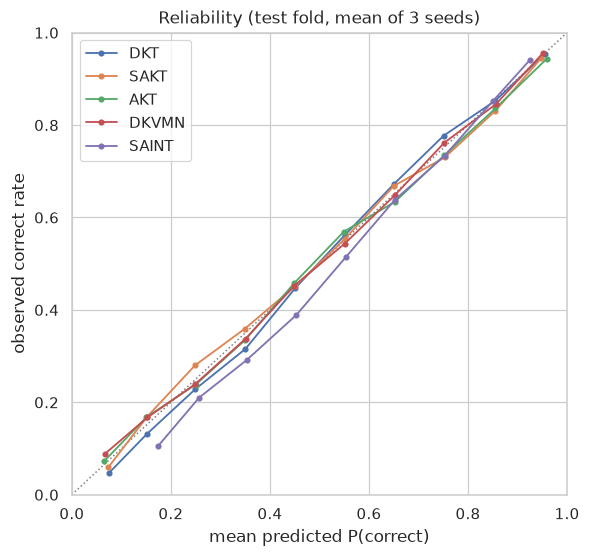

,position bin,n,correct_rate,DKT,SAKT,AKT,DKVMN,SAINT
0,2-10,2144,0.6381,0.8201,0.8153,0.8146,0.8167,0.7709
1,11-30,3853,0.6587,0.8528,0.8370,0.8587,0.8490,0.7929
2,31-100,6661,0.6706,0.8651,0.8604,0.8712,0.8697,0.7859
3,101-200,2065,0.6993,0.8765,0.8814,0.8851,0.8803,0.7310


table  -> data/benchmarks/report/tables/english_auc_by_position.tex


,model,epochs,best_epoch,s_per_epoch,params
0,AKT,30.00,20.00,17.72,301991
1,DKT,25.00,15.00,0.27,169056
2,DKVMN,26.33,16.33,2.72,41473
3,SAINT,38.00,31.33,3.59,440129
4,SAKT,25.00,15.00,0.77,81729


In [9]:
pa = per_answer_frame(WS, M)
mods = [m for m in M if m in pa]
fig, rel = reliability(pa, mods); ru.save_fig(fig, "english_reliability"); plt.show()
pa["position bin"] = analysis.position_bin(pa["position"])
by_pos = analysis.auc_by(pa, mods, "position bin").rename(columns=L); display(by_pos)
ru.save_table(by_pos, "english_auc_by_position", "Test AUC by answer position (English, synthetic; probabilities averaged over 3 seeds)", "tab:english-auc-position", digits=4)
runs = analysis.run_table(WS / "artifacts", M)
cost = runs.groupby("model").agg(epochs=("epochs_run", "mean"), best_epoch=("best_epoch", "mean"),
                                 s_per_epoch=("seconds_per_epoch", "mean"), params=("n_params", "first")).reset_index()
display(cost.round(2))

In [10]:
ru.sync_to_thesis()

14 figures -> thesis_docs/reports/DACN_HK261/figures/kt
30 tables -> thesis_docs/reports/DACN_HK261/tables/kt
